# Multivariate Data Analysis with Seaborn 
This notebook demonstrates common multivariate plots using seaborn.


In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style('whitegrid')

## Load built‑in datasets

In [13]:
tips = sns.load_dataset('tips')
flights = sns.load_dataset('flights')
iris = sns.load_dataset('iris')

## Create a manual dataframe

In [14]:
df = pd.DataFrame({
    'Pclass':[1,3,2,1,3],
    'Age':[38,22,26,35,28],
    'Sex':['female','male','female','female','male'],
    'Survived':[1,0,1,1,0],
    'Parch':[0,0,0,1,0]
})
df.head()

,Pclass,Age,Sex,Survived,Parch
0,1,38,female,1,0
1,3,22,male,0,0
2,2,26,female,1,0
3,1,35,female,1,1
4,3,28,male,0,0


## A) Numerical vs Numerical: Scatterplot

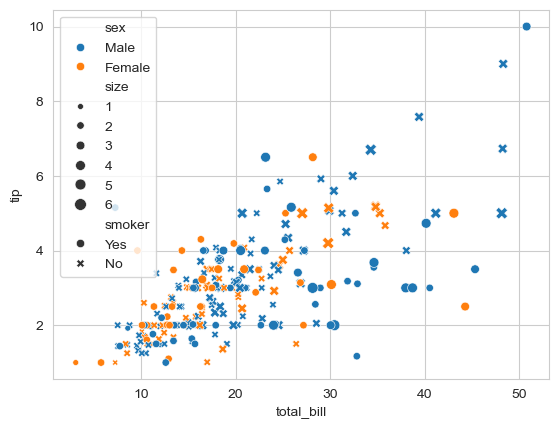

In [15]:
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='sex', style='smoker', size='size')
plt.show()

## B) Numerical vs Categorical: Barplot (mean estimator)

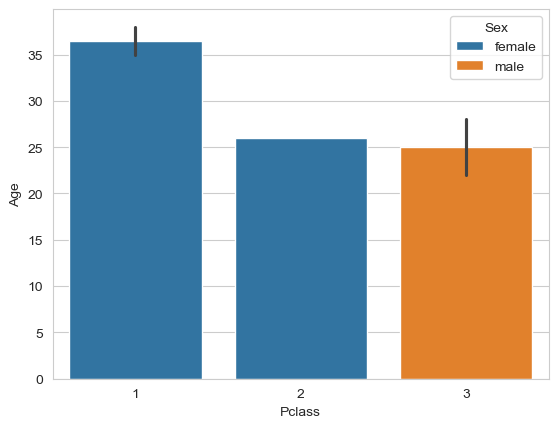

In [16]:
sns.barplot(data=df, x='Pclass', y='Age', hue='Sex')
plt.show()

## C) Numerical vs Categorical: Boxplot

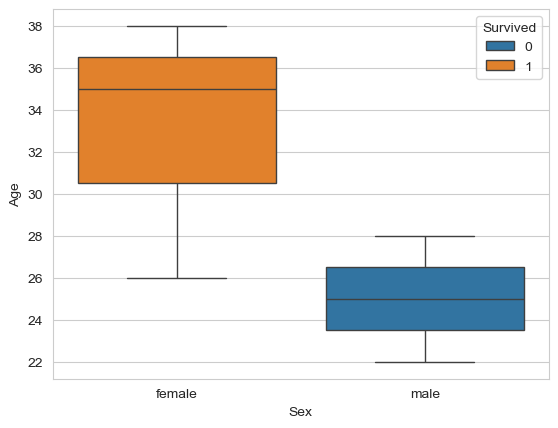

In [17]:
sns.boxplot(data=df, x='Sex', y='Age', hue='Survived')
plt.show()

## D) Distribution comparison using KDE

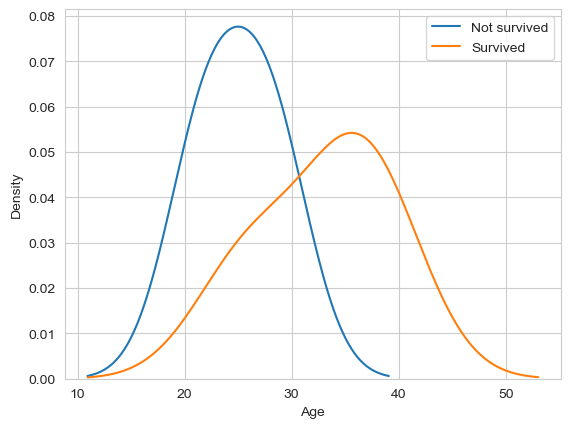

In [18]:
x = df[df['Survived']==0]
y = df[df['Survived']==1]

sns.kdeplot(data=x, x='Age', label='Not survived')
sns.kdeplot(data=y, x='Age', label='Survived')
plt.legend()
plt.show()

## E) Categorical vs Categorical: Crosstab + Heatmap

### Crosstab + Heatmap Explanation

```python
ct = pd.crosstab(df['Pclass'], df['Survived'])
sns.heatmap(ct, annot=True, fmt='d')
plt.show()
````

#### Step 1: Create Crosstab

`pd.crosstab(df['Pclass'], df['Survived'])`

* Builds a frequency table (contingency table).
* Rows represent passenger class (`Pclass`).
* Columns represent survival status (`Survived`).
* Each cell shows how many passengers fall into that class–survival combination.

Example structure:

| Pclass | Not Survived | Survived |
| ------ | ------------ | -------- |
| 1      | count        | count    |
| 2      | count        | count    |
| 3      | count        | count    |

The result is stored in variable `ct`.


#### Step 2: Draw Heatmap

`sns.heatmap(ct, annot=True, fmt='d')`

* Converts the table into a color-coded grid.
* Larger values usually appear with stronger color intensity.
* `annot=True` → prints the numeric values inside each cell.
* `fmt='d'` → displays numbers as integers (not decimals).



#### Step 3: Display Plot

`plt.show()`

* Renders the visualization.


### Interpretation Purpose

This visualization helps answer:

* Which passenger class had more survivors?
* Which class had more deaths?
* Is survival related to ticket class?

It is commonly used for **categorical vs categorical analysis**.


Survived,0,1
Pclass,,
1,0,2
2,0,1
3,2,0


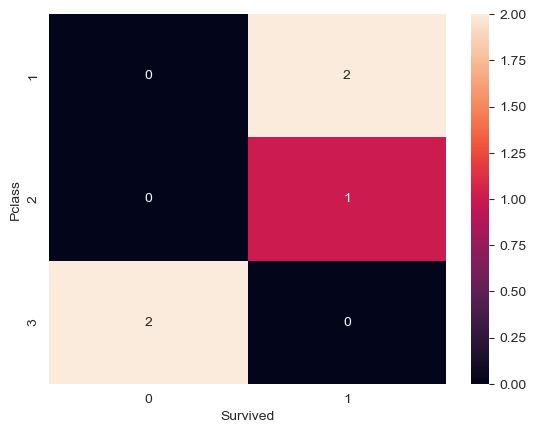

In [19]:
ct = pd.crosstab(df['Pclass'], df['Survived'])
display(ct)
sns.heatmap(ct, annot=True, fmt='d')
plt.show()

## F) Clustermap


### Clustermap of Crosstab (Parch vs Survived)

```python
sns.clustermap(pd.crosstab(df['Parch'], df['Survived']))
```


### Step 1: Create Crosstab

`pd.crosstab(df['Parch'], df['Survived'])`

* Produces a contingency table.
* `Parch` → number of parents/children travelling with the passenger.
* `Survived` → survival status (0 = No, 1 = Yes).
* Each cell contains the count of passengers for that combination.

Example idea:

| Parch | Not Survived | Survived |
| ----- | ------------ | -------- |
| 0     | count        | count    |
| 1     | count        | count    |
| 2     | count        | count    |


### Step 2: Apply Clustermap

`sns.clustermap(...)`

* Displays the table as a heatmap with hierarchical clustering.
* Rows and columns are automatically reordered based on similarity.
* A dendrogram (tree diagram) appears showing which groups are closer.

This means:

* Similar survival patterns for different `Parch` values will be grouped together.
* Categories with similar counts appear near each other.


### Why Use Clustermap Instead of Heatmap?

| Heatmap                  | Clustermap                        |
| ------------------------ | --------------------------------- |
| Shows raw table visually | Shows table + similarity grouping |
| Order stays fixed        | Order rearranged automatically    |
| No dendrogram            | Includes clustering tree          |


### Interpretation Purpose

This plot helps to explore:

* Whether family size (`Parch`) relates to survival.
* Which family groups behave similarly.
* Hidden patterns that are not obvious in a simple table.

Clustermap is useful for **finding structure and similarity inside categorical frequency data**.


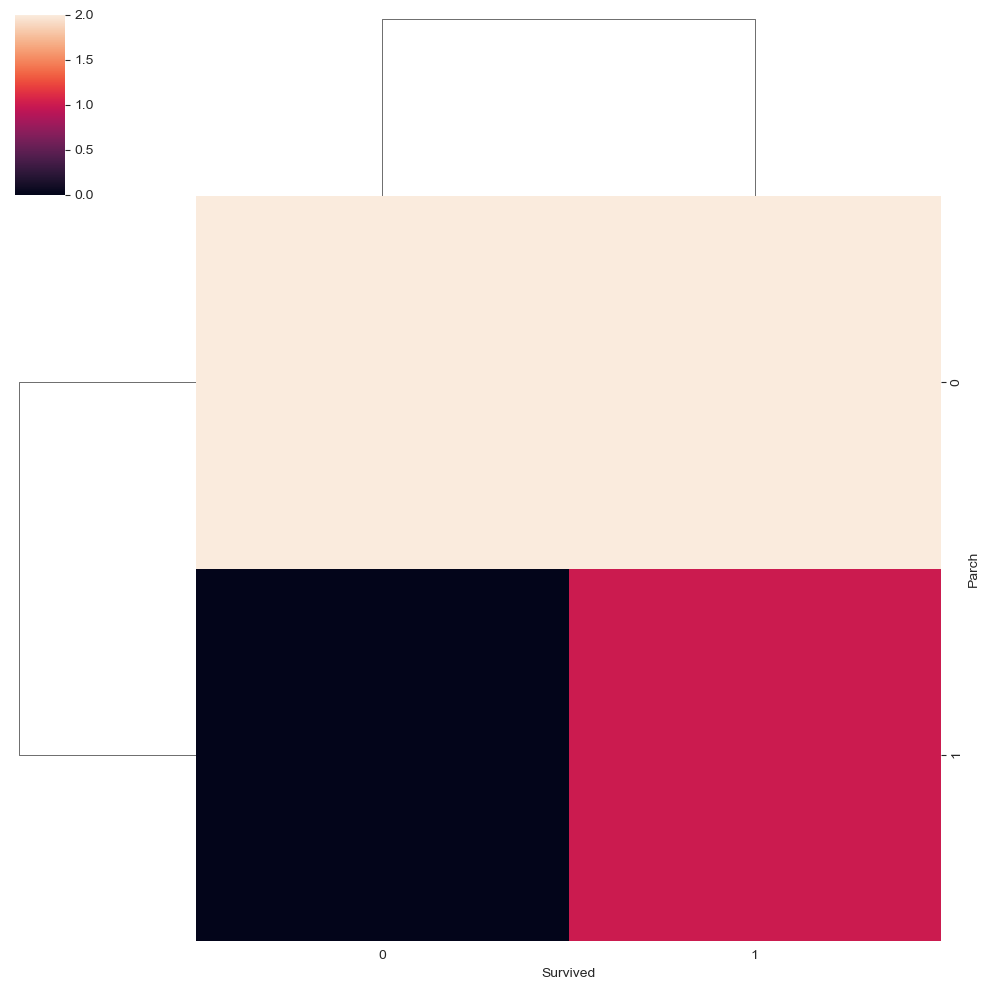

In [20]:
sns.clustermap(pd.crosstab(df['Parch'], df['Survived']))

## G) Pairplot for all numerical relationships

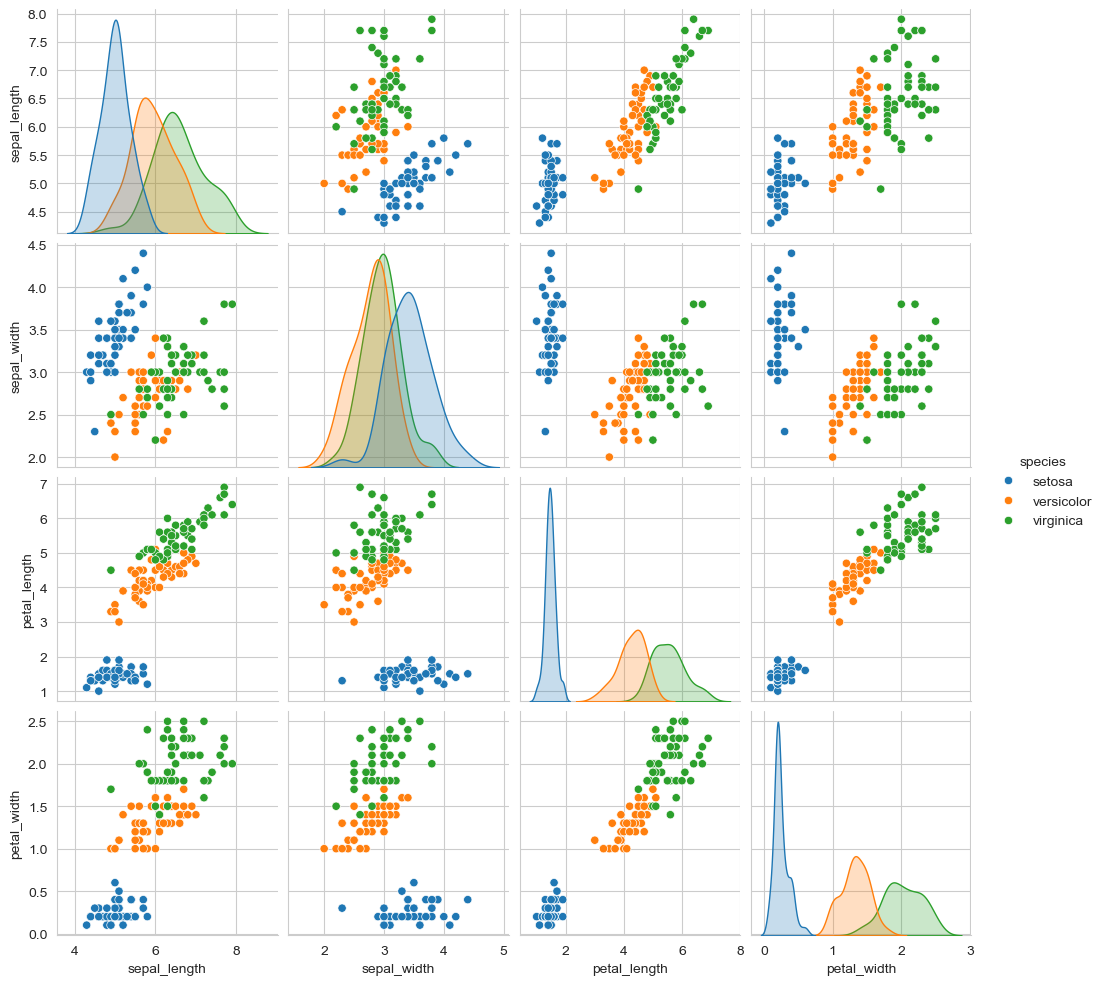

In [21]:
sns.pairplot(iris, hue='species')

## H) Time series style Lineplot

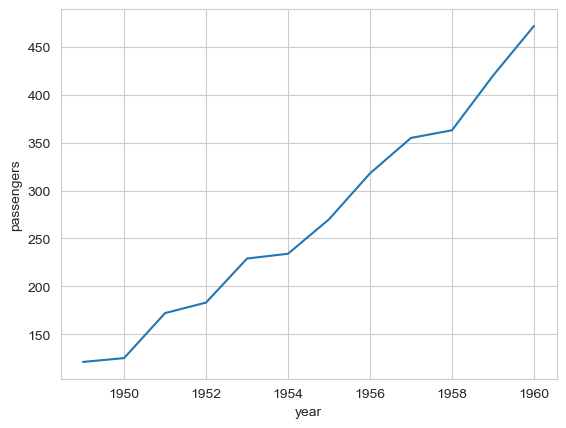

In [22]:
may_flights = flights.query("month == 'May'")
sns.lineplot(data=may_flights, x='year', y='passengers')
plt.show()